# This is a sample Jupyter Notebook

Below is an example of a code cell. 
Put your cursor into the cell and press Shift+Enter to execute it and select the next one, or click 'Run Cell' button.

Press Double Shift to search everywhere for classes, files, tool windows, actions, and settings.

To learn more about Jupyter Notebooks in PyCharm, see [help](https://www.jetbrains.com/help/pycharm/ipython-notebook-support.html).
For an overview of PyCharm, go to Help -> Learn IDE features or refer to [our documentation](https://www.jetbrains.com/help/pycharm/getting-started.html).

In [1]:
import pandas as pd
from Bio import SeqIO
from Bio.SeqUtils import gc_fraction

In [2]:
cds_counts = []
gc_counts = []
with open("EC_Oag.gbk", "r") as handle:
    for record in SeqIO.parse(handle, "genbank"):
        cds_count = 0
        print(f"ID: {record.id}")
        print(f"Name: {record.name}")
        print(f"Description: {record.description}")
        print(f"Sequence Length: {len(record.seq)}")
        for feature in record.features:
            if feature.type == "CDS":
                cds_count += 1
        print(f"CDS: {cds_count}")
        cds_counts.append(cds_count)
        gc_counts.append(gc_fraction(record.seq)*100)
        print("-" * 40)

ID: NZ_CP148474.1_reverse_complement
Name: NZ_CP148474.1_reverse_complement
Description: NZ_CP148474.1_reverse_complement, whole genome shotgun sequence
Sequence Length: 10745
CDS: 9
----------------------------------------
ID: NZ_CP010160.1_reverse_complement
Name: NZ_CP010160.1_reverse_complement
Description: NZ_CP010160.1_reverse_complement, whole genome shotgun sequence
Sequence Length: 13261
CDS: 12
----------------------------------------
ID: NC_017656.1_reverse_complement
Name: NC_017656.1_reverse_complement
Description: NC_017656.1_reverse_complement, whole genome shotgun sequence
Sequence Length: 10898
CDS: 10
----------------------------------------
ID: NZ_CP132728.1_reverse_complement
Name: NZ_CP132728.1_reverse_complement
Description: NZ_CP132728.1_reverse_complement, whole genome shotgun sequence
Sequence Length: 14348
CDS: 13
----------------------------------------
ID: NZ_CP021722.1_reverse_complement
Name: NZ_CP021722.1_reverse_complement
Description: NZ_CP021722.1_reve

In [3]:
import plotly.express as px

fig = px.histogram(cds_counts)
fig.show()

In [4]:

fig = px.histogram(gc_counts)
fig.show()

In [5]:
fig = px.scatter(cds_counts, gc_counts)
fig.show()
fig.show()

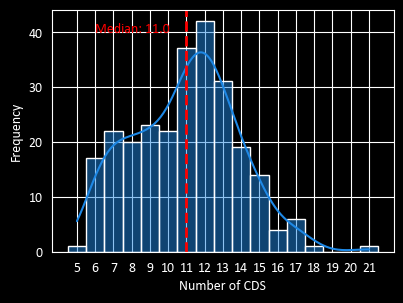

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import matplotlib as mpl
plt.figure(figsize=(4.135, 3.135))
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Calibri', 'DejaVu Sans'] # DejaVu Sans serves as a safe fallback
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42
sns.histplot(cds_counts, kde=True, discrete=True, color="#1E88E5")
plt.xticks(range(min(cds_counts), max(cds_counts)+1, 1))
plt.axvline(x=np.median(cds_counts), color="red", linestyle="--", linewidth=2)
plt.text(x=6, y=40, s=f"Median: {round(np.median(cds_counts), 2)}", color="red")
plt.ylabel("Frequency")
plt.xlabel("Number of CDS")
plt.tight_layout()
plt.savefig("cds_histogram.pdf", bbox_inches='tight', format="pdf")
plt.show()

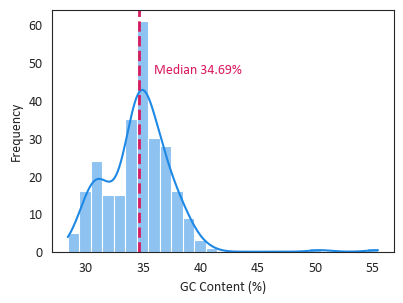

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import matplotlib as mpl
sns.set_style("white")
plt.figure(figsize=(4.135, 3.135))


# Set Calibri as the primary sans-serif font
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Calibri', 'DejaVu Sans'] # DejaVu Sans serves as a safe fallback
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42
sns.histplot(gc_counts, kde=True, color="#1E88E5")
#plt.xticks(range(min(gc_counts), max(gc_counts)+1, 1))
plt.axvline(x=np.median(gc_counts), color="#D81B60", linestyle="--", linewidth=2)
plt.text(x=36, y=47, s=f"Median {round(np.median(gc_counts), 2)}%", color="#D81B60")
plt.ylabel("Frequency")
plt.xlabel("GC Content (%)")
plt.tight_layout()
plt.savefig("gc_histogram.pdf", bbox_inches='tight', format="pdf")
plt.show()

In [8]:
import re
from Bio import SeqIO
from Bio.SeqUtils import gc_fraction
import pandas as pd

KEYWORDS = {
    "glycosyltransferase": [
        r"glycosyltransfer", r"GT\d+",
        r"(rhamnosyl|fucosyl|galactosyl|glucosyl|mannosyl)transfer",
    ],
    "sugar_biosynthesis": [
        r"NDP-sugar", r"nucleotide.?sugar",
        r"sugar\s+(synthase|epimerase|mutase|dehydratase|reductase|isomerase|aminotransferase)",
        r"(dTDP|UDP|GDP|CDP)-\w+\s+(biosynthesis|synthesis|formation)",
        r"rml[ABCD]", r"wba", r"rfb",
        r"(deoxysugar|deoxy.?hexose)",
    ],
    "wzx": [
        r"wzx", r"O-antigen flippase", r"flippase",
    ],
    "wzy": [
        r"wzy", r"O-antigen polymerase",
    ],
    "wzm": [
        r"wzm", r"O-antigen ABC transporter permease",
    ],
    "wzt": [
        r"wzt", r"O-antigen ABC transporter ATP[- ]binding",
    ],
}

combined = "|".join(
    f"(?P<{group}_{i}>{pat})"
    for group, patterns in KEYWORDS.items()
    for i, pat in enumerate(patterns)
)
PATTERN = re.compile(combined, re.IGNORECASE)

QUALIFIERS_TO_CHECK = ["product", "gene", "note", "function"]

rows = []

with open("EC_Oag.gbk") as fh:
    for record in SeqIO.parse(fh, "genbank"):
        for feature in record.features:
            if feature.type != "CDS":
                continue

            text = " | ".join(
                " ".join(feature.qualifiers.get(q, []))
                for q in QUALIFIERS_TO_CHECK
            )

            m = PATTERN.search(text)
            if not m:
                continue

            enzyme_class = next(
                k for k, v in m.groupdict().items() if v is not None
            ).rsplit("_", 1)[0]

            cds_seq = feature.extract(record.seq)
            gc = round(gc_fraction(cds_seq) * 100, 2)

            rows.append({
                "record":        record.id,
                "locus_tag":     feature.qualifiers.get("locus_tag", ["?"])[0],
                "gene":          feature.qualifiers.get("gene", ["?"])[0],
                "product":       feature.qualifiers.get("product", ["?"])[0],
                "enzyme_class":  enzyme_class,
                "start":         int(feature.location.start),
                "end":           int(feature.location.end),
                "strand":        feature.location.strand,
                "cds_length_bp": len(cds_seq),
                "gc_content":    gc,
            })

df = pd.DataFrame(rows)

# Summary stats per enzyme class
summary = (
    df.groupby("enzyme_class")["gc_content"]
    .agg(count="count", mean_gc="mean", median_gc="median", std_gc="std", min_gc="min", max_gc="max")
    .round(2)
    .reset_index()
)

print(df.to_string(index=False))
print("\n── GC content summary by enzyme class ──")
print(summary.to_string(index=False))

# Save
df.to_csv("gc_hits.tsv", sep="\t", index=False)
summary.to_csv("gc_summary.tsv", sep="\t", index=False)

FileNotFoundError: [Errno 2] No such file or directory: 'data/EC_Oag.gbk'

In [99]:
import numpy as np
from scipy import stats
from itertools import combinations

# ── Per-locus aggregation to avoid pseudoreplication ─────────────────────────
# Genes within the same locus are not independent observations: testing all
# CDS individually inflates n. Take the median GC of each enzyme class within
# each locus, then run PAIRED tests across loci containing both classes.
locus_medians = (
    df.pivot_table(index="record", columns="enzyme_class",
                   values="gc_content", aggfunc="median")
)

CLASS_ORDER = ["glycosyltransferase", "sugar_biosynthesis", "wzx", "wzy", "wzm", "wzt"]


Paired per-locus comparison (n = 101 loci containing both classes)
  median GT GC / locus:    30.97%
  median sugar GC / locus: 43.12%
  Wilcoxon signed-rank test: W = 1.0, p = 2.746e-18
  paired t-test (sensitivity): p = 1.051e-53

── Pairwise paired tests (per-locus medians; q = BH-FDR adjusted) ──
            class_a            class_b  n_loci  median_a  median_b  wilcoxon_p  paired_t_p  wilcoxon_q  paired_t_q
glycosyltransferase sugar_biosynthesis     101     31.08     43.00      0.0000      0.0000      0.0000      0.0000
glycosyltransferase                wzx     196     31.08     30.82      0.0377      0.0256      0.0424      0.0288
glycosyltransferase                wzy     193     31.08     28.91      0.0000      0.0000      0.0000      0.0000
glycosyltransferase                wzm       9     31.08     34.39      0.0195      0.0180      0.0251      0.0232
glycosyltransferase                wzt       9     31.08     38.56      0.3594      0.5611      0.3594      0.5611
 sugar_b

In [111]:
locus_medians_melted = locus_medians.melt()

gt = locus_medians_melted[locus_medians_melted.enzyme_class == "glycosyltransferase"]
sb = locus_medians_melted[locus_medians_melted.enzyme_class == "sugar_biosynthesis"]

wzx = locus_medians_melted[locus_medians_melted.enzyme_class == "wzx"]
wzy = locus_medians_melted[locus_medians_melted.enzyme_class == "wzy"]

wzm = locus_medians_melted[locus_medians_melted.enzyme_class == "wzm"]
wzt = locus_medians_melted[locus_medians_melted.enzyme_class == "wzt"]

print(gt.value.median())

print(sb.value.median())

print(wzx.value.median())

print(wzy.value.median())

print(wzm.value.median())

print(wzt.value.median())

31.085
43.0
30.82
28.91
34.39
38.555


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

glycosyltransferase vs. sugar_biosynthesis: Welch's t-test independent samples with Bonferroni correction, P_val:1.105e-186 t=-3.756e+01
wzy vs. wzm: Welch's t-test independent samples with Bonferroni correction, P_val:6.263e-03 t=-4.603e+00
wzx vs. wzm: Welch's t-test independent samples with Bonferroni correction, P_val:3.314e-02 t=-3.496e+00
wzy vs. wzt: Welch's t-test independent samples with Bonferroni correction, P_val:1.090e-03 t=-5.914e+00
wzx vs. wzt: Welch's t-test independent samples with Bonferroni correction, P_val:4.039e-03 t=-4.911e+00


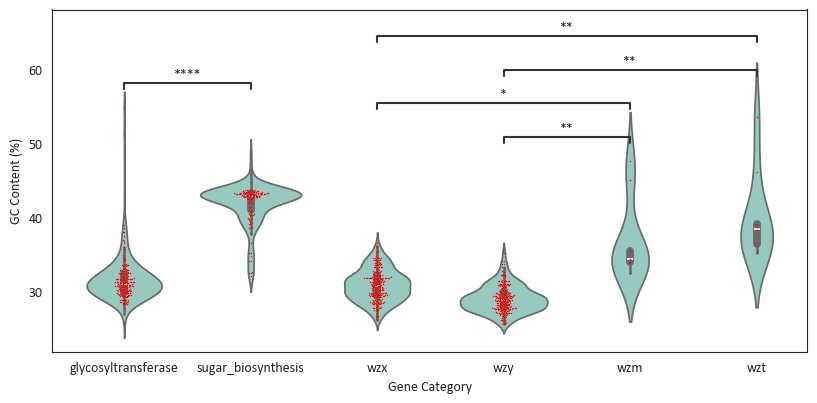

In [100]:
import seaborn as sns
from statannotations.Annotator import Annotator

plt.figure(figsize=(8.27, 4.135))
locus_medians_melted = locus_medians.melt()
sns.set_style("white")
# Set Calibri as the primary sans-serif font
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Calibri', 'DejaVu Sans'] # DejaVu Sans serves as a safe fallback
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42

ax0 = sns.violinplot(locus_medians_melted, y="value", x="enzyme_class", orient="v",  order=["glycosyltransferase", "sugar_biosynthesis", "wzx", "wzy", "wzm", "wzt"])

ax = sns.swarmplot(locus_medians_melted, y="value", x="enzyme_class", orient="v",  order=["glycosyltransferase", "sugar_biosynthesis", "wzx", "wzy", "wzm", "wzt"], size=1, c="red")

# Annotate with p-values from the paired per-locus Wilcoxon tests (see cell above)
# — the old per-CDS t-test inflated n by treating genes within a locus as independent.


annotator = Annotator(ax0, [("glycosyltransferase", "sugar_biosynthesis"), ("wzx", "wzm"), ("wzx", "wzt"), ("wzy", "wzm"), ("wzy", "wzt")], data=df, y="gc_content", x="enzyme_class", order= ["glycosyltransferase", "sugar_biosynthesis", "wzx", "wzy", "wzm", "wzt"])
annotator.configure(text_format='star', loc='inside', test='t-test_welch', comparisons_correction="Bonferroni")
#annotator.set_pvalues([p_gt_bs, p_wzx_wzy])
annotator.apply_test().annotate()


#ax.set_xticks(["Glycosyltransferases", "Sugar Biosynthesis"])
plt.xlabel("Gene Category")
plt.ylabel("GC Content (%)")
plt.tight_layout()
plt.savefig("gene_compare.pdf", bbox_inches='tight', format="pdf")
plt.show()

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

glycosyltransferase vs. sugar_biosynthesis: Custom statistical test, P_val:2.746e-18
wzx vs. wzy: Custom statistical test, P_val:9.123e-25


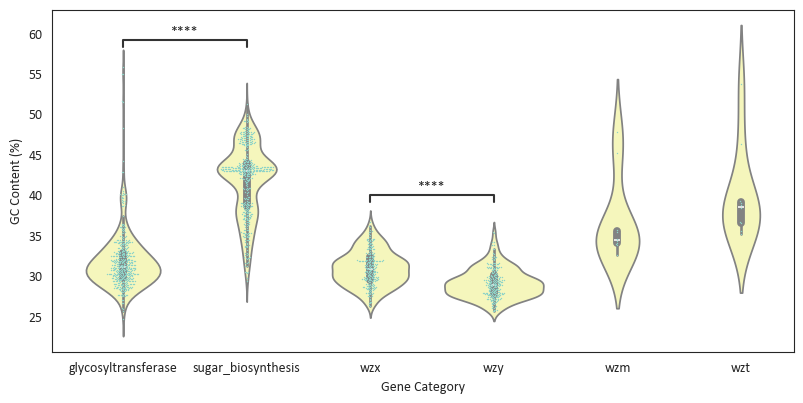

In [11]:
gtf = df[df.enzyme_class == "glycosyltransferase"]

gtf.gc_content.median()

np.float64(31.0)

In [12]:
gtf = df[df.enzyme_class == "sugar_biosynthesis"]

gtf.gc_content.median()

np.float64(43.0)